In [1]:
# Iris Flower Classification Project

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
# 1. Load Dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("Dataset loaded successfully!")
print(X.head())

Dataset loaded successfully!
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [5]:
# 2. Split Dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [6]:
# 3. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



Model: Logistic Regression
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



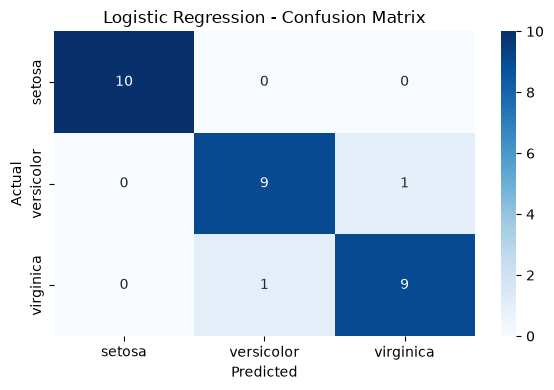


Model: Decision Tree
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



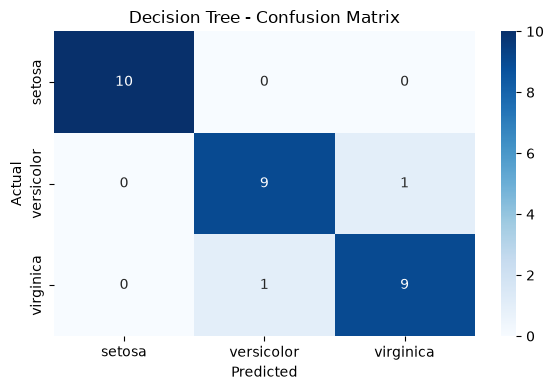

In [18]:
# 4. Train Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    print("\nModel:", name)
    print("Accuracy:", accuracy_score(y_test, predictions))

    print(classification_report(
        y_test,
        predictions,
        target_names=iris.target_names
    ))

    # 5. Confusion Matrix
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        cmap="Blues"
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


C:\Users\asus\AppData\Roaming\Python\Python314\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


<Figure size 800x600 with 0 Axes>

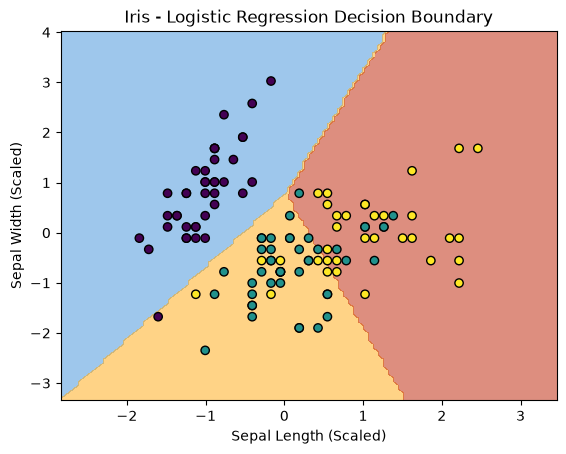

In [15]:
# 6. Decision Boundary Visualization

from sklearn.inspection import DecisionBoundaryDisplay

X_boundary = X.iloc[:, :2]
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_boundary, y, test_size=0.2, random_state=42, stratify=y
)

scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)

model = LogisticRegression(max_iter=200)
model.fit(X_train_b_scaled, y_train_b)

plt.figure(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    model,
    X_train_b_scaled,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.5
)

plt.scatter(
    X_train_b_scaled[:, 0],
    X_train_b_scaled[:, 1],
    c=y_train_b,
    edgecolors="black"
)

plt.title("Iris - Logistic Regression Decision Boundary")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.show()

In [19]:
print("\nProject completed successfully!")


Project completed successfully!
